# Uji Validitas dan Reliabilitas Instrumen Kuesioner

Mata Kuliah Statistika Probabilitas | Politeknik Caltex Riau
Nama: Yusuf Syamputra | Data: respons kuesioner kelas 3 TI B | Alat: Python (Google Colab)

## Langkah 1: Persiapan Lingkungan dan Impor Pustaka

In [1]:
import re
import textwrap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from google.colab import files

## Langkah 2: Unggah Berkas Data

In [2]:
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving data_3tib_bersih.xlsx to data_3tib_bersih.xlsx
File terbaca: data_3tib_bersih.xlsx


## Langkah 3: Membaca Data dan Memisahkan Butir

Data difilter ke kelas 3 TI B. Butir dipilih dari kolom berformat Dimensi [pernyataan] karena kolom non-butir pada data ini tidak hanya berada di depan (ada pertanyaan durasi gadget di tengah).

In [4]:
KELAS = "3 TI B"

df = pd.read_excel(nama_file)
df = df[df["Kelas"].astype(str).str.strip() == KELAS].reset_index(drop=True)

kolom_butir = [k for k in df.columns if re.search(r"\[.*\]\s*$", str(k))]
butir = df[kolom_butir]

print("Jumlah responden :", len(df))
print("Jumlah butir     :", butir.shape[1])
print("Data kosong      :", int(butir.isna().sum().sum()))

Jumlah responden : 41
Jumlah butir     : 29
Data kosong      : 0


## Langkah 4: Mengubah Jawaban Likert Menjadi Angka

In [5]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
}

num = butir.apply(lambda s: s.astype(str).str.strip().map(skala))

# Harus 0. Jika lebih dari 0, ada jawaban yang tidak terbaca.
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 0


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memeriksa kembali kebenaran informasi yang diberikan AI sebelum menggunakannya.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],...,Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Rsspon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Rsspon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Rsspon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Rsspon emosional [Saya merasa lega setelah berhasil mengumpulkan tugas meskipun pengerjaannya dilakukan AI saat mendekati deadline.],Rsspon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,4,2,5,2,4,2,5,4,2,2,...,1,1,2,1,2,4,2,5,4,5
1,4,5,5,4,4,4,5,4,4,2,...,1,2,1,1,1,4,5,4,2,4
2,2,2,4,1,1,4,5,2,1,1,...,1,2,2,2,3,2,2,4,2,5
3,4,5,5,4,2,4,5,2,4,1,...,2,1,5,1,5,1,2,4,2,4
4,5,5,5,5,2,5,5,5,5,2,...,1,5,5,5,5,1,1,5,5,4


## Langkah 5: Mengelompokkan Butir per Dimensi

In [12]:
ganti_nama = {
    "Penggunaan AI pada tugas atau projek kuliah": "Penggunaan AI pada Tugas atau Projek Kuliah",
    "Aspek Psikologis penggunaan AI pada tugas atau projek kuliah": "Aspek Psikologis Penggunaan AI pada Tugas atau Projek Kuliah",
    "Kebiasaan penggunaan teknologi digital": "Kebiasaan Penggunaan Teknologi Digital",
    "Prokrastinasi akademik.": "Prokrastinasi Akademik",
    "Rsspon emosional": "Respon Emosional",
}

dimensi = {}
for kolom in butir.columns:
    nama = re.match(r"^(.*?)\s*\[", kolom).group(1).strip()
    nama = ganti_nama.get(nama, nama)
    dimensi.setdefault(nama, []).append(kolom)

for nama, daftar in dimensi.items():
    print(f"{nama}: {len(daftar)} butir")

Penggunaan AI pada Tugas atau Projek Kuliah: 7 butir
Aspek Psikologis Penggunaan AI pada Tugas atau Projek Kuliah: 7 butir
Kebiasaan Penggunaan Teknologi Digital: 6 butir
Prokrastinasi Akademik: 4 butir
Respon Emosional: 5 butir


## Langkah 6: Uji Validitas (Korelasi Pearson Butir-Total)

In [13]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (α=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 41 | r tabel (α=0,05; df=39) = 0.308


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada Tugas atau Projek Kuliah,B1,0.710,0.557,0.0000,Valid
1,Penggunaan AI pada Tugas atau Projek Kuliah,B2,0.605,0.440,0.0000,Valid
2,Penggunaan AI pada Tugas atau Projek Kuliah,B3,0.394,0.137,0.0109,Valid
3,Penggunaan AI pada Tugas atau Projek Kuliah,B4,0.788,0.588,0.0000,Valid
4,Penggunaan AI pada Tugas atau Projek Kuliah,B5,0.638,0.339,0.0000,Valid
5,Penggunaan AI pada Tugas atau Projek Kuliah,B6,0.422,0.236,0.0060,Valid
6,Penggunaan AI pada Tugas atau Projek Kuliah,B7,0.086,-0.062,0.5936,Tidak valid
7,Aspek Psikologis Penggunaan AI pada Tugas atau...,B1,0.655,0.437,0.0000,Valid
8,Aspek Psikologis Penggunaan AI pada Tugas atau...,B2,0.698,0.497,0.0000,Valid
9,Aspek Psikologis Penggunaan AI pada Tugas atau...,B3,0.581,0.390,0.0001,Valid


## Langkah 7: Uji Reliabilitas (Cronbach's Alpha)

In [14]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas = []
alpha_dihapus = []

for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({
        "Dimensi": nama,
        "Jumlah butir": len(daftar),
        "Cronbach's alpha": round(a, 3),
        "Kategori": kategori(a),
    })
    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_dihapus.append({
                "Dimensi": nama,
                "Butir": f"B{i}",
                "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3),
            })

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada Tugas atau Projek Kuliah,7,0.604,Tidak reliabel
1,Aspek Psikologis Penggunaan AI pada Tugas atau...,7,0.635,Tidak reliabel
2,Kebiasaan Penggunaan Teknologi Digital,6,0.534,Tidak reliabel
3,Prokrastinasi Akademik,4,0.738,Reliabel
4,Respon Emosional,5,0.559,Tidak reliabel


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada Tugas atau Projek Kuliah,B1,0.490
1,Penggunaan AI pada Tugas atau Projek Kuliah,B2,0.534
2,Penggunaan AI pada Tugas atau Projek Kuliah,B3,0.627
3,Penggunaan AI pada Tugas atau Projek Kuliah,B4,0.441
4,Penggunaan AI pada Tugas atau Projek Kuliah,B5,0.569
5,Penggunaan AI pada Tugas atau Projek Kuliah,B6,0.591
6,Penggunaan AI pada Tugas atau Projek Kuliah,B7,0.645
7,Aspek Psikologis Penggunaan AI pada Tugas atau...,B1,0.565
8,Aspek Psikologis Penggunaan AI pada Tugas atau...,B2,0.542
9,Aspek Psikologis Penggunaan AI pada Tugas atau...,B3,0.585


## Langkah 8: Menggabungkan dan Mengunduh Hasil

In [15]:
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")

with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
    gabung.to_excel(w, sheet_name="Validitas", index=False)
    tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)

files.download("hasil_uji_validitas_reliabilitas.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Langkah 9: Analisis Deskriptif per Dimensi

Bagian ini diminta template laporan. Statistik dihitung dari skor total tiap dimensi. Kurtosis yang dipakai adalah excess kurtosis (0 = setara sebaran normal).

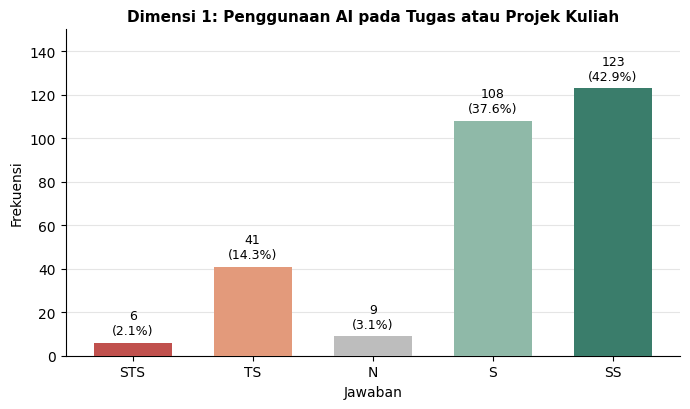

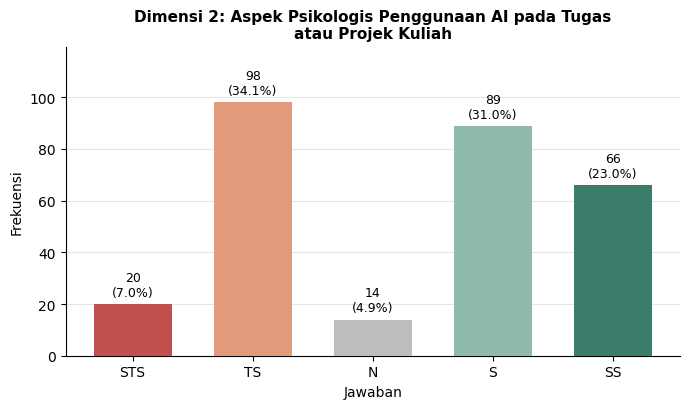

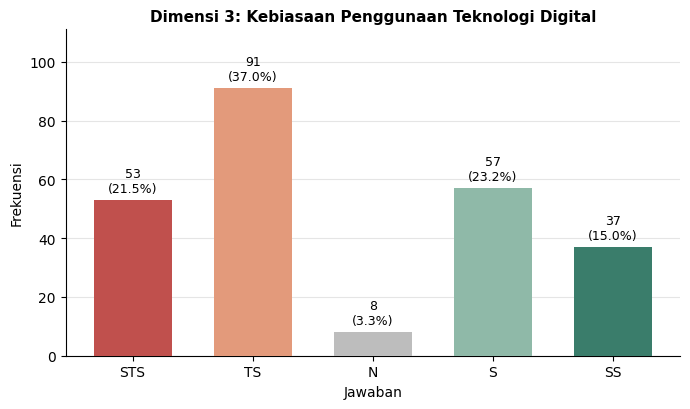

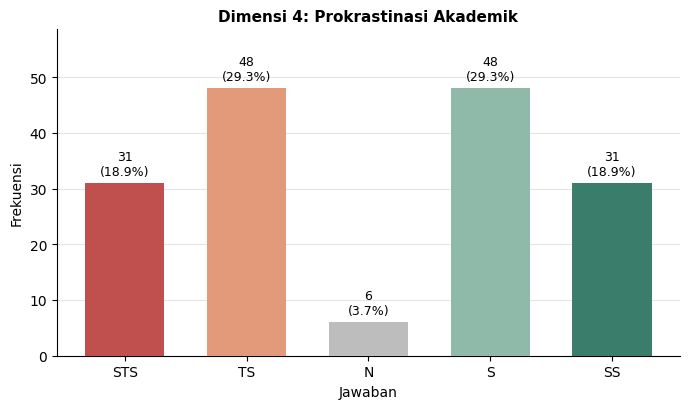

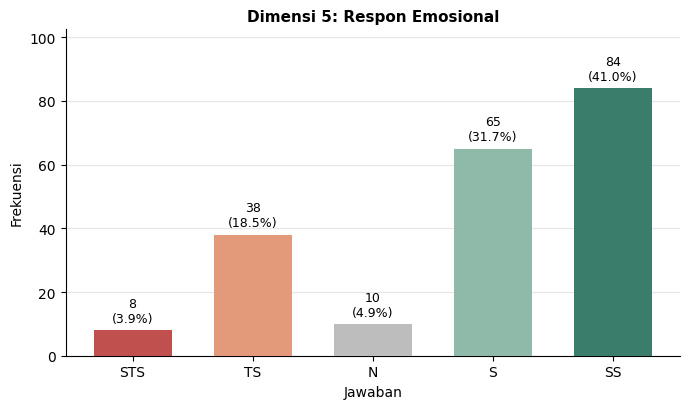

,Dimensi,Rata-rata skor total,Std deviasi,Skewness,Kurtosis
0,Penggunaan AI pada Tugas atau Projek Kuliah,28.341,3.468,-0.374,0.116
1,Aspek Psikologis Penggunaan AI pada Tugas atau...,23.024,4.327,0.136,0.984
2,Kebiasaan Penggunaan Teknologi Digital,16.390,3.859,0.019,-0.243
3,Prokrastinasi Akademik,12.000,4.319,-0.215,-0.729
4,Respon Emosional,19.366,3.562,-0.808,0.293


In [16]:
label = ["STS", "TS", "N", "S", "SS"]
warna = ["#C0504D", "#E39A7B", "#BDBDBD", "#8FB9A8", "#3A7D6B"]

hasil_deskriptif = []

for d, (nama, daftar) in enumerate(dimensi.items(), 1):
    x = num[daftar]
    total = x.sum(axis=1)
    freq = pd.Series(x.values.ravel()).value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
    persen = freq / freq.sum() * 100

    hasil_deskriptif.append({
        "Dimensi": nama,
        "Rata-rata skor total": round(total.mean(), 3),
        "Std deviasi": round(total.std(ddof=1), 3),
        "Skewness": round(stats.skew(total, bias=False), 3),
        "Kurtosis": round(stats.kurtosis(total, bias=False), 3),
    })

    fig, ax = plt.subplots(figsize=(7, 4.2))
    batang = ax.bar(label, freq.values, color=warna, width=0.65, zorder=3)
    for b, f, p in zip(batang, freq.values, persen):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + freq.max() * 0.02,
                f"{f}\n({p:.1f}%)", ha="center", va="bottom", fontsize=9)

    ax.set_ylim(0, freq.max() * 1.22)
    ax.set_title("\n".join(textwrap.wrap(f"Dimensi {d}: {nama}", 55)),
                 fontsize=11, fontweight="bold")
    ax.set_xlabel("Jawaban")
    ax.set_ylabel("Frekuensi")
    ax.grid(axis="y", color="#E5E5E5", zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.savefig(f"grafik_dimensi_{d}.png", dpi=200)
    plt.show()

tabel_deskriptif = pd.DataFrame(hasil_deskriptif)
tabel_deskriptif

In [11]:
import zipfile

with zipfile.ZipFile("grafik_dimensi.zip", "w") as z:
    for d in range(1, len(dimensi) + 1):
        z.write(f"grafik_dimensi_{d}.png")

files.download("grafik_dimensi.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>